In [311]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.model_selection import train_test_split , RandomizedSearchCV
from sklearn.linear_model import LinearRegression , Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.metrics import(r2_score , mean_absolute_error,mean_squared_error)
from sklearn.preprocessing import OneHotEncoder

In [312]:
df=pd.read_csv("../dataset/used_car_price.csv")

In [313]:
df.head()

,make_year,mileage_kmpl,engine_cc,fuel_type,owner_count,price_usd,brand,transmission,color,service_history,accidents_reported,insurance_valid
0,2001,8.17,4000,Petrol,4,8587.64,Chevrolet,Manual,White,NaN,0,No
1,2014,17.59,1500,Petrol,4,5943.50,Honda,Manual,Black,NaN,0,Yes
2,2023,18.09,2500,Diesel,5,9273.58,BMW,Automatic,Black,Full,1,Yes
3,2009,11.28,800,Petrol,1,6836.24,Hyundai,Manual,Blue,Full,0,Yes
4,2005,12.23,1000,Petrol,2,4625.79,Nissan,Automatic,Red,Full,0,Yes


In [314]:
df.tail()

,make_year,mileage_kmpl,engine_cc,fuel_type,owner_count,price_usd,brand,transmission,color,service_history,accidents_reported,insurance_valid
9995,1996,15.25,1500,Petrol,2,5498.71,Hyundai,Manual,Silver,NaN,0,Yes
9996,1997,14.45,5000,Diesel,1,9588.31,Honda,Manual,Gray,Full,0,Yes
9997,2002,19.41,1000,Diesel,4,4557.10,Kia,Manual,Black,Full,0,Yes
9998,2005,12.95,4000,Petrol,5,7413.59,BMW,Automatic,Blue,Full,0,Yes
9999,2007,18.81,5000,Petrol,1,11634.09,BMW,Automatic,Silver,Full,0,Yes


In [315]:
df.shape

(10000, 12)

In [316]:
df.info

<bound method DataFrame.info of       make_year  mileage_kmpl  engine_cc fuel_type  owner_count  price_usd  \
0          2001          8.17       4000    Petrol            4    8587.64   
1          2014         17.59       1500    Petrol            4    5943.50   
2          2023         18.09       2500    Diesel            5    9273.58   
3          2009         11.28        800    Petrol            1    6836.24   
4          2005         12.23       1000    Petrol            2    4625.79   
...         ...           ...        ...       ...          ...        ...   
9995       1996         15.25       1500    Petrol            2    5498.71   
9996       1997         14.45       5000    Diesel            1    9588.31   
9997       2002         19.41       1000    Diesel            4    4557.10   
9998       2005         12.95       4000    Petrol            5    7413.59   
9999       2007         18.81       5000    Petrol            1   11634.09   

          brand transmission   

In [317]:
df.describe()

,make_year,mileage_kmpl,engine_cc,owner_count,price_usd,accidents_reported
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,2009.206900,17.960753,2287.130000,3.003500,7179.754532,0.492200
std,8.373858,5.025486,1291.276927,1.418904,2795.270940,0.694109
min,1995.000000,5.000000,800.000000,1.000000,1000.000000,0.000000
25%,2002.000000,14.540000,1200.000000,2.000000,5176.547500,0.000000
50%,2009.000000,17.970000,1800.000000,3.000000,6961.260000,0.000000
75%,2016.000000,21.352500,3000.000000,4.000000,8993.732500,1.000000
max,2023.000000,35.000000,5000.000000,5.000000,17647.630000,5.000000


In [318]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
make_year,10000.0,2009.206900,8.373858,1995.0,2002.0000,2009.00,2016.0000,2023.00
mileage_kmpl,10000.0,17.960753,5.025486,5.0,14.5400,17.97,21.3525,35.00
engine_cc,10000.0,2287.130000,1291.276927,800.0,1200.0000,1800.00,3000.0000,5000.00
owner_count,10000.0,3.003500,1.418904,1.0,2.0000,3.00,4.0000,5.00
price_usd,10000.0,7179.754532,2795.270940,1000.0,5176.5475,6961.26,8993.7325,17647.63
accidents_reported,10000.0,0.492200,0.694109,0.0,0.0000,0.00,1.0000,5.00


In [319]:
df.columns

Index(['make_year', 'mileage_kmpl', 'engine_cc', 'fuel_type', 'owner_count',
       'price_usd', 'brand', 'transmission', 'color', 'service_history',
       'accidents_reported', 'insurance_valid'],
      dtype='object')

In [320]:
df.nunique()

make_year               29
mileage_kmpl          2213
engine_cc               10
fuel_type                3
owner_count              5
price_usd             9906
brand                   10
transmission             2
color                    6
service_history          2
accidents_reported       6
insurance_valid          2
dtype: int64

In [321]:
df.nunique(dropna=False)

make_year               29
mileage_kmpl          2213
engine_cc               10
fuel_type                3
owner_count              5
price_usd             9906
brand                   10
transmission             2
color                    6
service_history          3
accidents_reported       6
insurance_valid          2
dtype: int64

In [322]:
categorical_columns = df.select_dtypes(include='object').columns
categorical_columns

Index(['fuel_type', 'brand', 'transmission', 'color', 'service_history',
       'insurance_valid'],
      dtype='object')

In [323]:
for col in categorical_columns:
    print(f"\nUnique values in  {col}:")
    print(df[col].unique())


Unique values in  fuel_type:
['Petrol' 'Diesel' 'Electric']

Unique values in  brand:
['Chevrolet' 'Honda' 'BMW' 'Hyundai' 'Nissan' 'Tesla' 'Toyota' 'Kia'
 'Volkswagen' 'Ford']

Unique values in  transmission:
['Manual' 'Automatic']

Unique values in  color:
['White' 'Black' 'Blue' 'Red' 'Gray' 'Silver']

Unique values in  service_history:
[nan 'Full' 'Partial']

Unique values in  insurance_valid:
['No' 'Yes']


In [324]:
df['fuel_type'].unique()

array(['Petrol', 'Diesel', 'Electric'], dtype=object)

In [325]:
for col in categorical_columns:
    print(f"\nValue counts for {col}:")
    print(df[col].value_counts(dropna=False))


Value counts for fuel_type:
fuel_type
Petrol      4968
Diesel      4058
Electric     974
Name: count, dtype: int64

Value counts for brand:
brand
Nissan        1089
Volkswagen    1033
BMW           1021
Tesla         1006
Honda         1003
Chevrolet      999
Hyundai        989
Toyota         956
Kia            955
Ford           949
Name: count, dtype: int64

Value counts for transmission:
transmission
Manual       5985
Automatic    4015
Name: count, dtype: int64

Value counts for color:
color
Gray      1705
Black     1702
Red       1678
White     1651
Blue      1634
Silver    1630
Name: count, dtype: int64

Value counts for service_history:
service_history
Full       4987
Partial    2975
NaN        2038
Name: count, dtype: int64

Value counts for insurance_valid:
insurance_valid
Yes    7934
No     2066
Name: count, dtype: int64


In [326]:
pd.crosstab(df['brand'], df['fuel_type'])

fuel_type,Diesel,Electric,Petrol
brand,,,
BMW,427,104,490
Chevrolet,399,93,507
Ford,372,103,474
Honda,389,99,515
Hyundai,396,89,504
Kia,385,107,463
Nissan,451,118,520
Tesla,433,88,485
Toyota,400,80,476


In [327]:
df.isnull().sum()

make_year                0
mileage_kmpl             0
engine_cc                0
fuel_type                0
owner_count              0
price_usd                0
brand                    0
transmission             0
color                    0
service_history       2038
accidents_reported       0
insurance_valid          0
dtype: int64

In [328]:
df.isnull().sum()/len(df) * 100

make_year              0.00
mileage_kmpl           0.00
engine_cc              0.00
fuel_type              0.00
owner_count            0.00
price_usd              0.00
brand                  0.00
transmission           0.00
color                  0.00
service_history       20.38
accidents_reported     0.00
insurance_valid        0.00
dtype: float64

In [329]:
missing = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100
})

missing

,Missing Values,Missing Percentage
make_year,0,0.00
mileage_kmpl,0,0.00
engine_cc,0,0.00
fuel_type,0,0.00
owner_count,0,0.00
price_usd,0,0.00
brand,0,0.00
transmission,0,0.00
color,0,0.00
service_history,2038,20.38


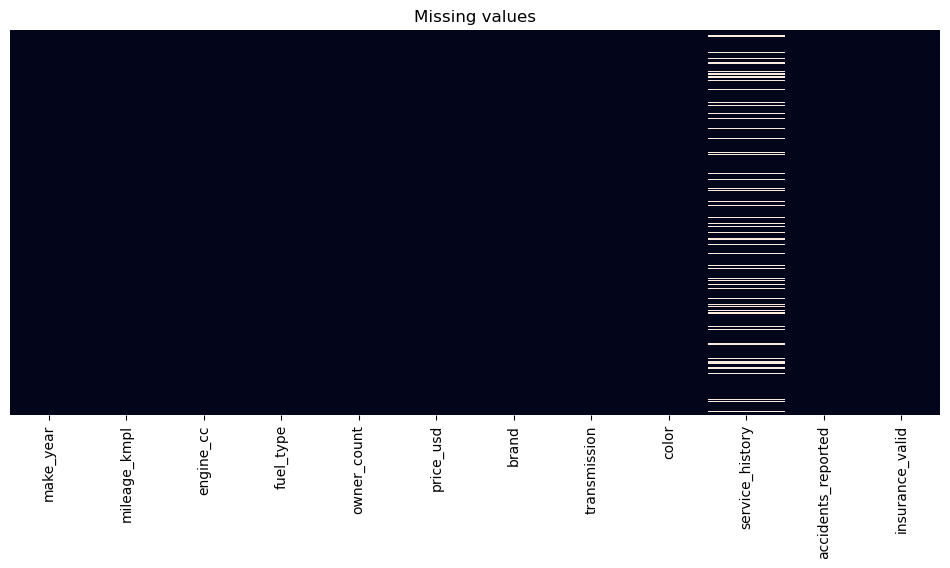

In [330]:
plt.figure(figsize=(12,5))
sns.heatmap(df.isnull(),cbar=False,yticklabels=False)
plt.title('Missing values')
plt.show()

In [331]:
df['service_history'].value_counts(dropna=False)

service_history
Full       4987
Partial    2975
NaN        2038
Name: count, dtype: int64

In [332]:
df['service_history'].value_counts(normalize=True,
                                 dropna=False)*100

service_history
Full       49.87
Partial    29.75
NaN        20.38
Name: proportion, dtype: float64

In [333]:
df.groupby('service_history', dropna=False)['price_usd'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

,count,mean,median,min,max
service_history,,,,,
Full,4987,7224.995657,7017.790,1000.0,17647.63
Partial,2975,7142.997311,6892.920,1000.0,15872.61
NaN,2038,7122.706075,6915.815,1000.0,17155.52


In [334]:
df.duplicated().sum()

np.int64(0)

In [335]:
df['service_history']=df['service_history'].fillna('Unknown')

In [336]:
df.isnull().sum()

make_year             0
mileage_kmpl          0
engine_cc             0
fuel_type             0
owner_count           0
price_usd             0
brand                 0
transmission          0
color                 0
service_history       0
accidents_reported    0
insurance_valid       0
dtype: int64

In [337]:
df['service_history'].value_counts()

service_history
Full       4987
Partial    2975
Unknown    2038
Name: count, dtype: int64

In [338]:
df.dtypes

make_year               int64
mileage_kmpl          float64
engine_cc               int64
fuel_type              object
owner_count             int64
price_usd             float64
brand                  object
transmission           object
color                  object
service_history        object
accidents_reported      int64
insurance_valid        object
dtype: object

In [339]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   make_year           10000 non-null  int64  
 1   mileage_kmpl        10000 non-null  float64
 2   engine_cc           10000 non-null  int64  
 3   fuel_type           10000 non-null  object 
 4   owner_count         10000 non-null  int64  
 5   price_usd           10000 non-null  float64
 6   brand               10000 non-null  object 
 7   transmission        10000 non-null  object 
 8   color               10000 non-null  object 
 9   service_history     10000 non-null  object 
 10  accidents_reported  10000 non-null  int64  
 11  insurance_valid     10000 non-null  object 
dtypes: float64(2), int64(4), object(6)
memory usage: 937.6+ KB


In [340]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
make_year,10000.0,2009.206900,8.373858,1995.0,2002.0000,2009.00,2016.0000,2023.00
mileage_kmpl,10000.0,17.960753,5.025486,5.0,14.5400,17.97,21.3525,35.00
engine_cc,10000.0,2287.130000,1291.276927,800.0,1200.0000,1800.00,3000.0000,5000.00
owner_count,10000.0,3.003500,1.418904,1.0,2.0000,3.00,4.0000,5.00
price_usd,10000.0,7179.754532,2795.270940,1000.0,5176.5475,6961.26,8993.7325,17647.63
accidents_reported,10000.0,0.492200,0.694109,0.0,0.0000,0.00,1.0000,5.00


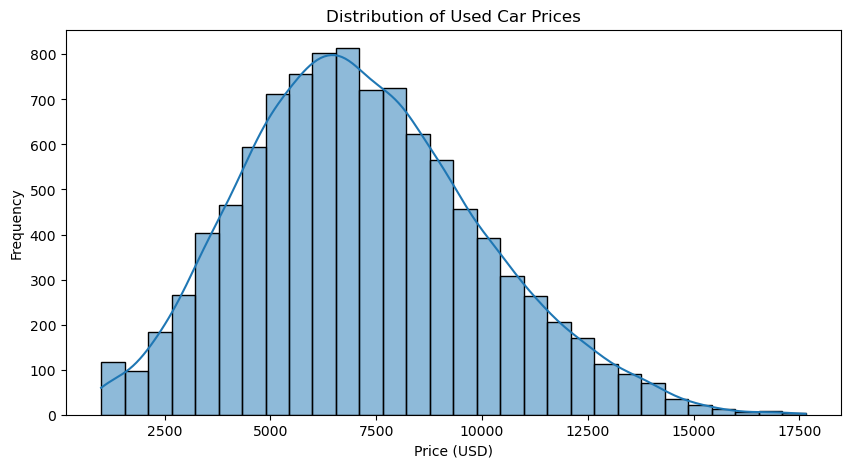

In [341]:
plt.figure(figsize=(10, 5))
sns.histplot(
    data=df,
    x='price_usd',
    bins=30,
    kde=True
)
plt.title('Distribution of Used Car Prices')
plt.xlabel('Price (USD)')
plt.ylabel('Frequency')

plt.show()

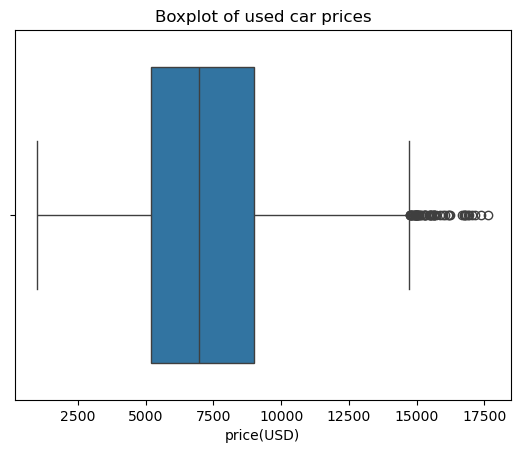

In [342]:
plt.Figure(figsize=(10,4))
sns.boxplot(x=df['price_usd'])
plt.title('Boxplot of used car prices')
plt.xlabel('price(USD)')
plt.show()

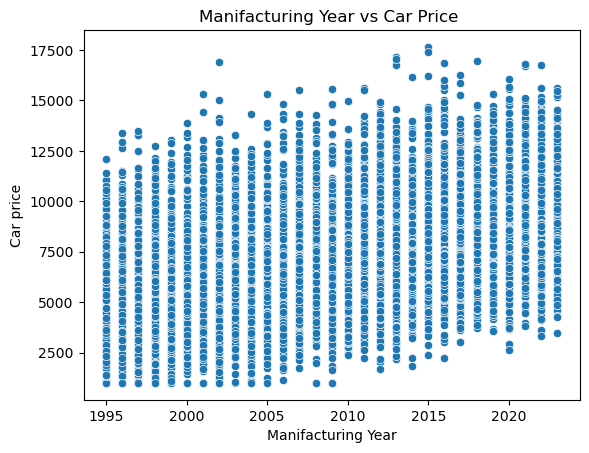

In [343]:
plt.Figure(figsize=(10,5))
sns.scatterplot(
    data=df,
    x='make_year',
    y='price_usd'
)
plt.title('Manifacturing Year vs Car Price ')
plt.xlabel('Manifacturing Year')
plt.ylabel('Car price')
plt.show()

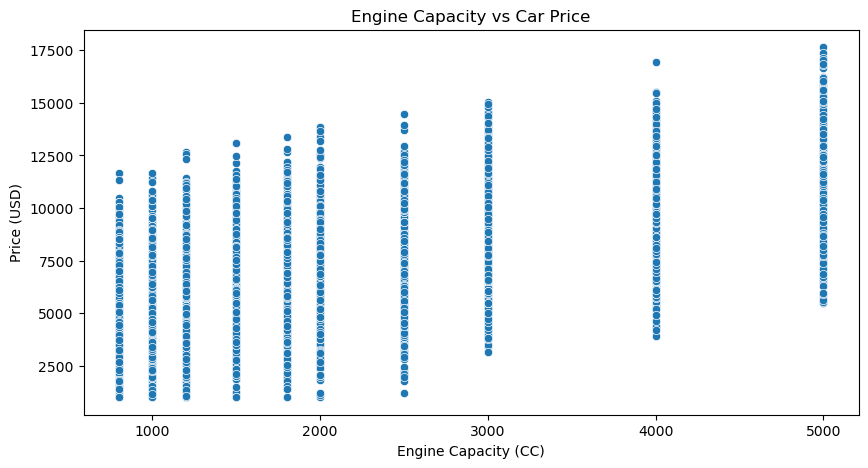

In [344]:
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df,
    x='engine_cc',
    y='price_usd'
)
plt.title('Engine Capacity vs Car Price')
plt.xlabel('Engine Capacity (CC)')
plt.ylabel('Price (USD)')
plt.show()

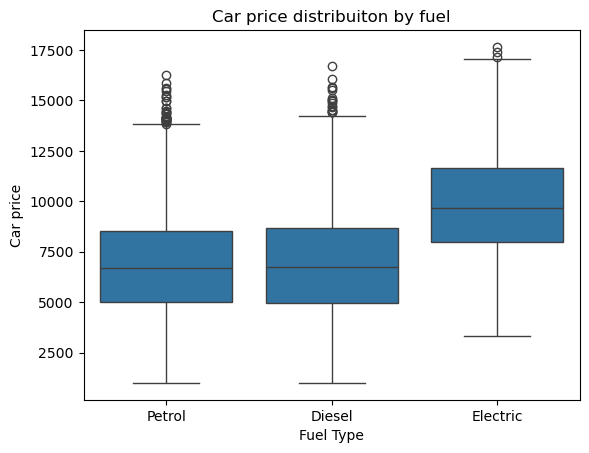

In [345]:
plt.Figure(figsize=(10,5))
sns.boxplot(
    data=df,
    x='fuel_type',
    y='price_usd'
)
plt.title('Car price distribuiton by fuel')
plt.xlabel('Fuel Type')
plt.ylabel('Car price')
plt.show()

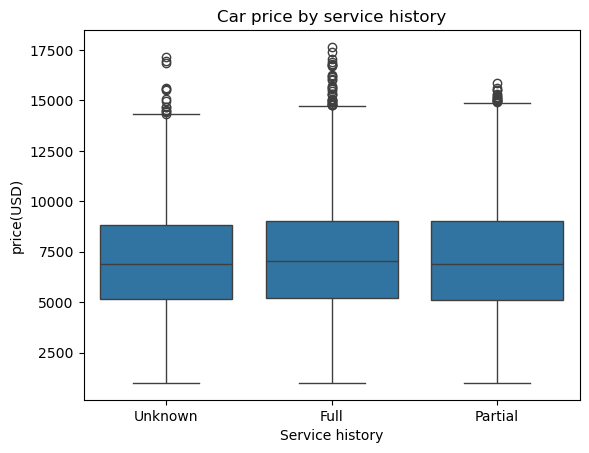

In [346]:
plt.Figure(figsize=(8,5))
sns.boxplot(data=df,x='service_history',y='price_usd')
plt.title('Car price by service history')
plt.xlabel('Service history')
plt.ylabel('price(USD)')
plt.show()

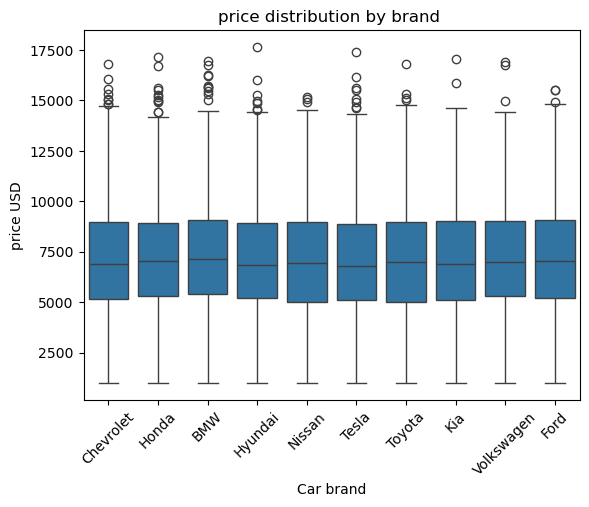

In [347]:
plt.Figure(figsize=(12,6))
sns.boxplot(data=df,x='brand',y='price_usd')
plt.title("price distribution by brand ")
plt.xlabel('Car brand')
plt.ylabel('price USD')
plt.xticks(rotation=45)
plt.show()

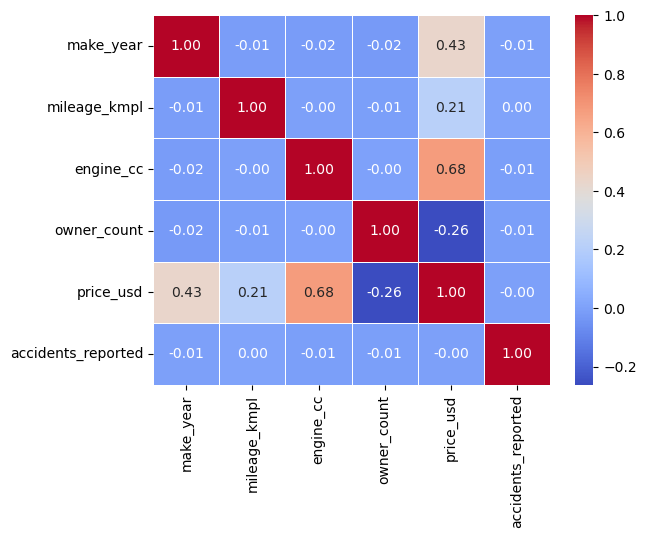

In [348]:
numeric_df=df.select_dtypes(include=np.number)
correlation_matrix=numeric_df.corr()
plt.Figure(figsize=(10,7))
sns.heatmap(correlation_matrix,annot=True,cmap='coolwarm',fmt='.2f',linewidths=0.5)
plt.show()

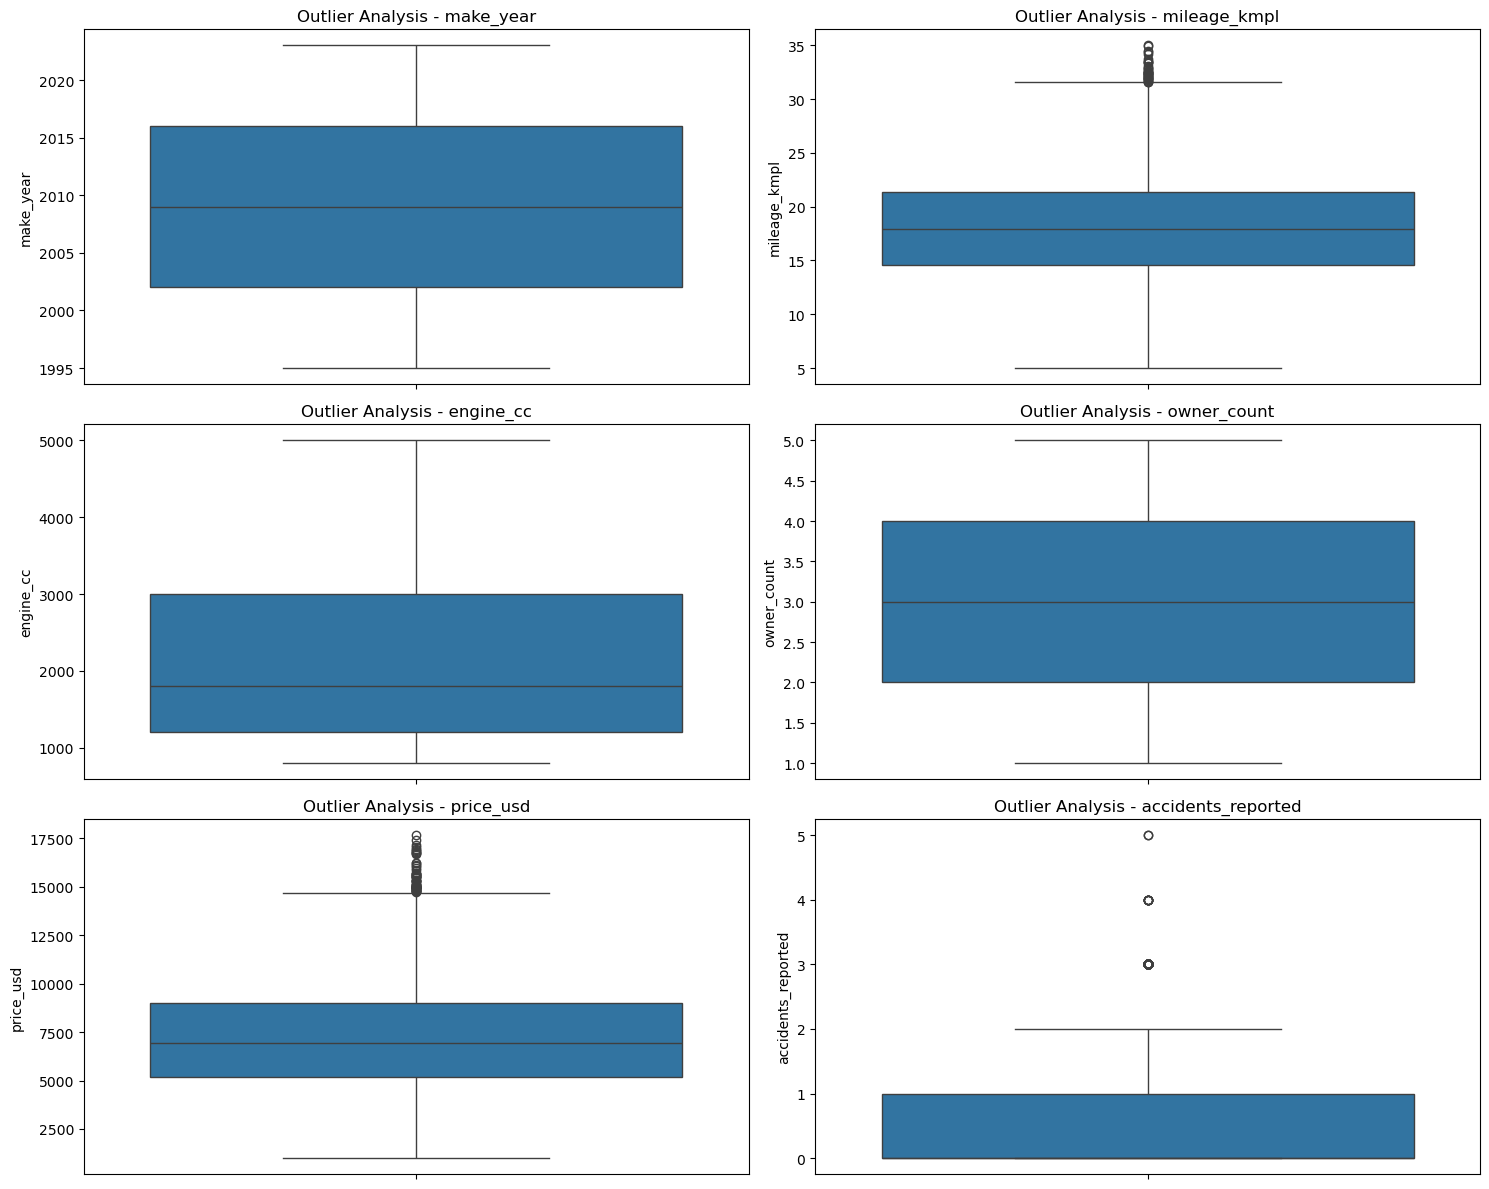

In [349]:
numeric_columns = [
    'make_year',
    'mileage_kmpl',
    'engine_cc',
    'owner_count',
    'price_usd',
    'accidents_reported'
]
plt.figure(figsize=(15, 12))
for i, column in enumerate(numeric_columns, 1):
    plt.subplot(3, 2, i)
    sns.boxplot(y=df[column])
    plt.title(f'Outlier Analysis - {column}')
plt.tight_layout()
plt.show()

In [350]:
for column in numeric_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    print(f'{column}: {len(outliers)} potential outliers')

make_year: 0 potential outliers
mileage_kmpl: 36 potential outliers
engine_cc: 0 potential outliers
owner_count: 0 potential outliers
price_usd: 58 potential outliers
accidents_reported: 130 potential outliers


In [351]:
for column in ['mileage_kmpl', 'price_usd', 'accidents_reported']:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    print(f'\nColumn: {column}')
    print(f'Lower Limit: {lower_limit:.2f}')
    print(f'Upper Limit: {upper_limit:.2f}')
    print(f'Minimum Outlier: {outliers[column].min()}')
    print(f'Maximum Outlier: {outliers[column].max()}')


Column: mileage_kmpl
Lower Limit: 4.32
Upper Limit: 31.57
Minimum Outlier: 31.61
Maximum Outlier: 35.0

Column: price_usd
Lower Limit: -549.23
Upper Limit: 14719.51
Minimum Outlier: 14740.7
Maximum Outlier: 17647.63

Column: accidents_reported
Lower Limit: -1.50
Upper Limit: 2.50
Minimum Outlier: 3
Maximum Outlier: 5


In [352]:
X = df.drop('price_usd',axis=1)
Y = df['price_usd']

In [353]:
print('Independent Features:',X.shape)
print('Target Variable:',Y.shape)

Independent Features: (10000, 11)
Target Variable: (10000,)


In [354]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=42)

In [355]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", Y_train.shape)
print("y_test:", Y_test.shape)

X_train: (8000, 11)
X_test: (2000, 11)
y_train: (8000,)
y_test: (2000,)


In [356]:
numeric_features= X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include='object').columns.to_list()
print("Numerical Features:",numeric_features)
print("\nCategorical Features:",categorical_features)

Numerical Features: ['make_year', 'mileage_kmpl', 'engine_cc', 'owner_count', 'accidents_reported']

Categorical Features: ['fuel_type', 'brand', 'transmission', 'color', 'service_history', 'insurance_valid']


In [357]:
encoder=OneHotEncoder(handle_unknown='ignore',sparse_output=False)
X_train_encoded=encoder.fit_transform(X_train[categorical_features])
X_test_encoded=encoder.transform(X_test[categorical_features])

In [358]:
encoded_columns= encoder.get_feature_names_out(categorical_features)
X_train_encoded_df = pd.DataFrame(
    X_train_encoded,columns=encoded_columns,index=X_train.index
)

X_test_encoded_df = pd.DataFrame(
    X_test_encoded,
    columns=encoded_columns,
    index=X_test.index
)

In [375]:
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train[numeric_features])
X_test_scaled = scaler.transform(X_test[numeric_features])

In [376]:
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=numeric_features,
    index=X_train.index
)

X_test_scaled_df = pd.DataFrame(
    X_test_scaled,
    columns=numeric_features,
    index=X_test.index
)

In [377]:
X_train_processed = pd.concat(
    [X_train_scaled_df, X_train_encoded_df],
    axis=1
)

X_test_processed = pd.concat(
    [X_test_scaled_df, X_test_encoded_df],
    axis=1
)

In [365]:
print("Training Data:", X_train_processed.shape)
print("Testing Data:", X_test_processed.shape)

print("Training Missing Values:", X_train_processed.isnull().sum().sum())
print("Testing Missing Values:", X_test_processed.isnull().sum().sum())

Training Data: (8000, 31)
Testing Data: (2000, 31)
Training Missing Values: 0
Testing Missing Values: 0


In [363]:
LR_model = LinearRegression()
LR_model.fit(X_train_processed,Y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [379]:
LR_predictions = LR_model.predict(X_test_processed)
LR_predictions

array([12124.39047004,  4688.22168024,  7061.90011434, ...,
       13362.16796146,  9606.13107056,  3343.09729718], shape=(2000,))

In [393]:
LR_r2 = r2_score(Y_test,LR_predictions)
LR_mae = mean_absolute_error(Y_test,LR_predictions)
LR_mse = mean_squared_error(Y_test,LR_predictions)
LR_rmse = np.sqrt(LR_mse)
print("Linear Regression performance")
print("-----------------------------")
print("R2 Score:",LR_r2)
print("MAE:",LR_mae)
print("MSE:",LR_mse)
print("RMSE:",LR_rmse)

Linear Regression performance
-----------------------------
R2 Score: 0.8765494410543437
MAE: 791.0023773132338
MSE: 982113.671995924
RMSE: 991.0164842200779


In [396]:
DT_model = DecisionTreeRegressor(random_state=42)
DT_model.fit(X_train_processed,Y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [398]:
DT_predictions = DT_model.predict(X_test_processed)
DT_predictions

array([ 9232.11,  5055.81,  6903.96, ..., 11277.26,  9595.14,  4572.19],
      shape=(2000,))

In [401]:
DT_r2 = r2_score(Y_test, DT_predictions)
DT_mae = mean_absolute_error(Y_test, DT_predictions)
DT_mse = mean_squared_error(Y_test, DT_predictions)
DT_rmse = np.sqrt(DT_mse)

print("Decision Tree Regression Performance")
print("------------------------------------")
print("R2 Score:", DT_r2)
print("MAE:", DT_mae)
print("MSE:", DT_mse)
print("RMSE:", DT_rmse)

Decision Tree Regression Performance
------------------------------------
R2 Score: 0.6996888334901281
MAE: 1228.71135
MSE: 2389132.1756770997
RMSE: 1545.6817834460946


In [408]:
tree_counts = [50, 100, 200, 300, 500]

tree_results = []

for n in tree_counts:

    model = RandomForestRegressor(
        n_estimators=n,
        random_state=42,
        n_jobs=-1,
        oob_score=True
    )

    model.fit(X_train_processed, Y_train)

    tree_results.append({
        "Number of Trees": n,
        "OOB R2 Score": model.oob_score_
    })

tree_results_df = pd.DataFrame(tree_results)

tree_results_df

,Number of Trees,OOB R2 Score
0,50,0.840206
1,100,0.845195
2,200,0.847484
3,300,0.848132
4,500,0.848543


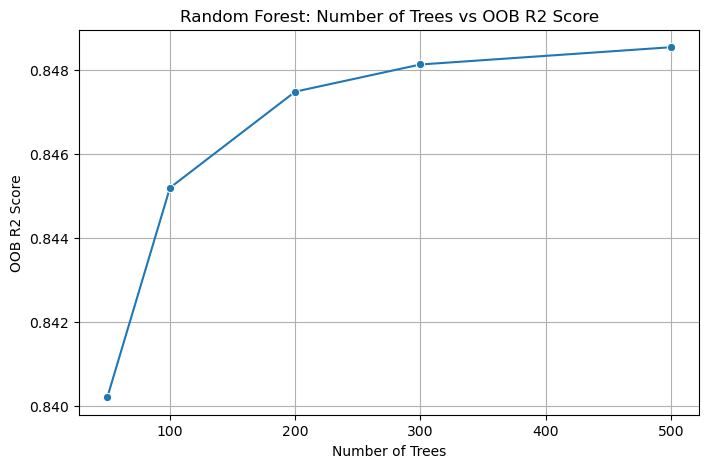

In [409]:
plt.figure(figsize=(8, 5))

sns.lineplot(
    data=tree_results_df,
    x="Number of Trees",
    y="OOB R2 Score",
    marker="o"
)

plt.title("Random Forest: Number of Trees vs OOB R2 Score")
plt.xlabel("Number of Trees")
plt.ylabel("OOB R2 Score")
plt.grid(True)
plt.show()

In [410]:
RF_model = RandomForestRegressor(n_estimators=300,random_state=42,n_jobs=-1)

In [411]:
RF_model.fit(X_train_processed,Y_train)

,n_estimators,300
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [412]:
RF_predictions = RF_model.predict(X_test_processed)

In [413]:
RF_r2 = r2_score(Y_test, RF_predictions)
RF_mae = mean_absolute_error(Y_test, RF_predictions)
RF_mse = mean_squared_error(Y_test, RF_predictions)
RF_rmse = np.sqrt(RF_mse)

print("Random Forest Regression Performance")
print("-------------------------------------")
print("R2 Score:", RF_r2)
print("MAE:", RF_mae)
print("MSE:", RF_mse)
print("RMSE:", RF_rmse)

Random Forest Regression Performance
-------------------------------------
R2 Score: 0.8522004126041505
MAE: 865.8671695333335
MSE: 1175822.9102933342
RMSE: 1084.3536832110333


In [ ]:
KNN_model = KNeighborsRegressor(n_neighbors=5)

In [414]:
KNN_model.fit(X_train_processed,Y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [416]:
KNN_predictions = KNN_model.predict(X_test_processed)

In [418]:
KNN_r2 = r2_score(Y_test, KNN_predictions)
KNN_mae = mean_absolute_error(Y_test, KNN_predictions)
KNN_mse = mean_squared_error(Y_test, KNN_predictions)
KNN_rmse = np.sqrt(KNN_mse)

print("KNN Regression Performance")
print("--------------------------")
print("R2 Score:", KNN_r2)
print("MAE:", KNN_mae)
print("MSE:", KNN_mse)
print("RMSE:", KNN_rmse)

KNN Regression Performance
--------------------------
R2 Score: 0.7372182323287965
MAE: 1146.83944
MSE: 2090566.207114176
RMSE: 1445.8790430441186


In [419]:
SVR_model = SVR(kernel='rbf')

In [420]:
SVR_model.fit(X_train_processed,Y_train)

,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,tol,0.001
,C,1.0
,epsilon,0.1
,shrinking,True
,cache_size,200
,verbose,False
,max_iter,-1


In [421]:
SVR_predictions = SVR_model.predict(X_test_processed)

In [422]:
SVR_r2 = r2_score(Y_test, SVR_predictions)
SVR_mae = mean_absolute_error(Y_test, SVR_predictions)
SVR_mse = mean_squared_error(Y_test, SVR_predictions)
SVR_rmse = np.sqrt(SVR_mse)

print("SVR Regression Performance")
print("--------------------------")
print("R2 Score:", SVR_r2)
print("MAE:", SVR_mae)
print("MSE:", SVR_mse)
print("RMSE:", SVR_rmse)

SVR Regression Performance
--------------------------
R2 Score: 0.11642292367806106
MAE: 2105.858700593197
MSE: 7029317.115526079
RMSE: 2651.2859362064437


In [423]:
final_result = [
    {
        "Model Name": "Linear Regression",
        "R2 Score": LR_r2,
        "MAE": LR_mae,
        "MSE": LR_mse,
        "RMSE": LR_rmse
    },
    {
        "Model Name": "Decision Tree",
        "R2 Score": DT_r2,
        "MAE": DT_mae,
        "MSE": DT_mse,
        "RMSE": DT_rmse
    },
    {
        "Model Name": "Random Forest",
        "R2 Score": RF_r2,
        "MAE": RF_mae,
        "MSE": RF_mse,
        "RMSE": RF_rmse
    },
    {
        "Model Name": "KNN",
        "R2 Score": KNN_r2,
        "MAE": KNN_mae,
        "MSE": KNN_mse,
        "RMSE": KNN_rmse
    },
    {
        "Model Name": "SVR",
        "R2 Score": SVR_r2,
        "MAE": SVR_mae,
        "MSE": SVR_mse,
        "RMSE": SVR_rmse
    }
]

final_result_df = pd.DataFrame(final_result)

final_result_df = final_result_df.sort_values(
    by="R2 Score",
    ascending=False
)

final_result_df

,Model Name,R2 Score,MAE,MSE,RMSE
0,Linear Regression,0.876549,791.002377,9.821137e+05,991.016484
2,Random Forest,0.852200,865.867170,1.175823e+06,1084.353683
3,KNN,0.737218,1146.839440,2.090566e+06,1445.879043
1,Decision Tree,0.699689,1228.711350,2.389132e+06,1545.681783
4,SVR,0.116423,2105.858701,7.029317e+06,2651.285936


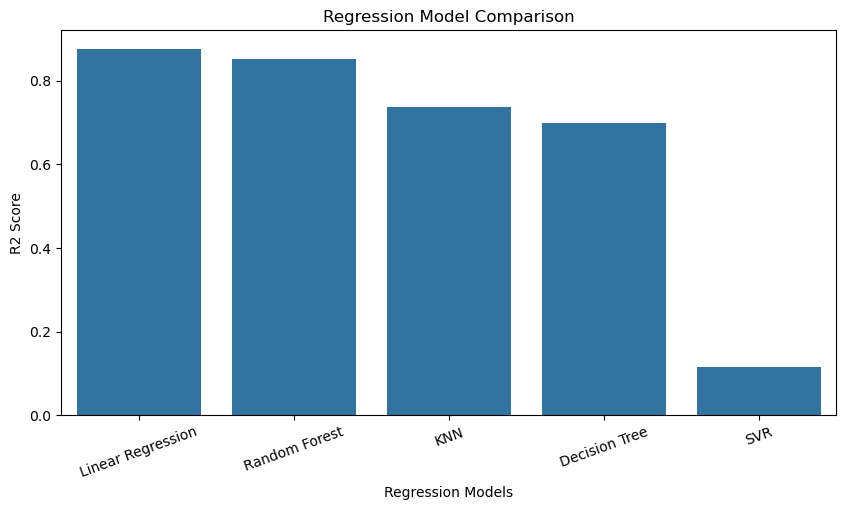

In [424]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=final_result_df,
    x="Model Name",
    y="R2 Score"
)

plt.title("Regression Model Comparison")
plt.xlabel("Regression Models")
plt.ylabel("R2 Score")
plt.xticks(rotation=20)
plt.show()

In [425]:
RF_params = {
    'n_estimators': [100, 200, 300, 400],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 1.0]
}

In [431]:
RF_random_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ),
    param_distributions=RF_params
)

In [432]:
RF_random_search.fit(X_train_processed,Y_train)

,estimator,RandomForestR...ndom_state=42)
,param_distributions,"{'max_depth': [None, 10, ...], 'max_features': ['sqrt', 1.0], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,n_iter,10
,scoring,None
,n_jobs,None
,refit,True
,cv,None
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


In [433]:
print("Best Parameters:", RF_random_search.best_params_)
print("Best Cross Validation R2:", RF_random_search.best_score_)

Best Parameters: {'n_estimators': 400, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_features': 1.0, 'max_depth': 10}
Best Cross Validation R2: 0.8517229994985076


In [434]:
RF_best_model = RF_random_search.best_estimator_
RF_best_predictions = RF_best_model.predict(X_test_processed)

RF_best_r2 = r2_score(Y_test, RF_best_predictions)
RF_best_mae = mean_absolute_error(Y_test, RF_best_predictions)
RF_best_mse = mean_squared_error(Y_test, RF_best_predictions)
RF_best_rmse = np.sqrt(RF_best_mse)

print("Tuned Random Forest Performance")
print("--------------------------------")
print("R2 Score:", RF_best_r2)
print("MAE:", RF_best_mae)
print("MSE:", RF_best_mse)
print("RMSE:", RF_best_rmse)

Tuned Random Forest Performance
--------------------------------
R2 Score: 0.8573377425459835
MAE: 849.2054168081294
MSE: 1134952.7674886403
RMSE: 1065.3416200865524


In [437]:
final_result.append({
    "Model Name": "Tuned Random Forest",
    "R2_score":RF_best_r2,
    "MAE":RF_best_mae,
    "MSE":RF_best_mse,
    "RMSE":RF_best_rmse
})

In [438]:
final_result_df = pd.DataFrame(final_result)
final_result_df = final_result_df.sort_values(
    by="R2 Score",
    ascending=False
)
final_result_df

,Model Name,R2 Score,MAE,MSE,RMSE,R2_score
0,Linear Regression,0.876549,791.002377,9.821137e+05,991.016484,NaN
2,Random Forest,0.852200,865.867170,1.175823e+06,1084.353683,NaN
3,KNN,0.737218,1146.839440,2.090566e+06,1445.879043,NaN
1,Decision Tree,0.699689,1228.711350,2.389132e+06,1545.681783,NaN
4,SVR,0.116423,2105.858701,7.029317e+06,2651.285936,NaN
5,Tuned Random Forest,NaN,NaN,NaN,NaN,RF_best_r2
6,Tuned Random Forest,NaN,849.205417,NaN,NaN,0.857338
7,Tuned Random Forest,NaN,849.205417,1.134953e+06,1065.341620,0.857338


In [439]:
DT_params = {
    'max_depth': [None, 5, 10, 15, 20, 30],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 4, 8],
    'max_features': [None, 'sqrt', 'log2']
}

In [440]:
DT_random_search = RandomizedSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_distributions=DT_params
)

In [442]:
DT_random_search.fit(X_train_processed, Y_train)

,estimator,DecisionTreeR...ndom_state=42)
,param_distributions,"{'max_depth': [None, 5, ...], 'max_features': [None, 'sqrt', ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...]}"
,n_iter,10
,scoring,None
,n_jobs,None
,refit,True
,cv,None
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


In [443]:
print("Best Parameters:", DT_random_search.best_params_)
print("Best Cross Validation R2:", DT_random_search.best_score_)

Best Parameters: {'min_samples_split': 20, 'min_samples_leaf': 8, 'max_features': None, 'max_depth': 30}
Best Cross Validation R2: 0.8090060239042483


In [444]:
DT_best_model = DT_random_search.best_estimator_
DT_best_predictions = DT_best_model.predict(X_test_processed)

DT_best_r2 = r2_score(Y_test, DT_best_predictions)
DT_best_mae = mean_absolute_error(Y_test, DT_best_predictions)
DT_best_mse = mean_squared_error(Y_test, DT_best_predictions)
DT_best_rmse = np.sqrt(DT_best_mse)

print("Tuned Decision Tree Performance")
print("--------------------------------")
print("R2 Score:", DT_best_r2)
print("MAE:", DT_best_mae)
print("MSE:", DT_best_mse)
print("RMSE:", DT_best_rmse)

Tuned Decision Tree Performance
--------------------------------
R2 Score: 0.8173665696216021
MAE: 952.5096702341791
MSE: 1452944.3241897249
RMSE: 1205.381401959448


In [445]:
final_result = [
    {
        "Model Name": "Linear Regression",
        "R2 Score": LR_r2,
        "MAE": LR_mae,
        "MSE": LR_mse,
        "RMSE": LR_rmse
    },
    {
        "Model Name": "Decision Tree",
        "R2 Score": DT_r2,
        "MAE": DT_mae,
        "MSE": DT_mse,
        "RMSE": DT_rmse
    },
    {
        "Model Name": "Tuned Decision Tree",
        "R2 Score": DT_best_r2,
        "MAE": DT_best_mae,
        "MSE": DT_best_mse,
        "RMSE": DT_best_rmse
    },
    {
        "Model Name": "Random Forest",
        "R2 Score": RF_r2,
        "MAE": RF_mae,
        "MSE": RF_mse,
        "RMSE": RF_rmse
    },
    {
        "Model Name": "Tuned Random Forest",
        "R2 Score": RF_best_r2,
        "MAE": RF_best_mae,
        "MSE": RF_best_mse,
        "RMSE": RF_best_rmse
    },
    {
        "Model Name": "KNN",
        "R2 Score": KNN_r2,
        "MAE": KNN_mae,
        "MSE": KNN_mse,
        "RMSE": KNN_rmse
    },
    {
        "Model Name": "SVR",
        "R2 Score": SVR_r2,
        "MAE": SVR_mae,
        "MSE": SVR_mse,
        "RMSE": SVR_rmse
    }
]

final_result_df = pd.DataFrame(final_result)

final_result_df = final_result_df.sort_values(
    by="R2 Score",
    ascending=False
).reset_index(drop=True)

final_result_df

,Model Name,R2 Score,MAE,MSE,RMSE
0,Linear Regression,0.876549,791.002377,9.821137e+05,991.016484
1,Tuned Random Forest,0.857338,849.205417,1.134953e+06,1065.341620
2,Random Forest,0.852200,865.867170,1.175823e+06,1084.353683
3,Tuned Decision Tree,0.817367,952.509670,1.452944e+06,1205.381402
4,KNN,0.737218,1146.839440,2.090566e+06,1445.879043
5,Decision Tree,0.699689,1228.711350,2.389132e+06,1545.681783
6,SVR,0.116423,2105.858701,7.029317e+06,2651.285936


In [446]:
KNN_params = {
    'n_neighbors': [3, 5, 7, 9, 11, 15, 20, 25, 30],
    'weights': ['uniform', 'distance'],
    'p': [1, 2]
}

In [447]:
KNN_random_search = RandomizedSearchCV(
    estimator=KNeighborsRegressor(),
    param_distributions=KNN_params
)

In [448]:
KNN_random_search.fit(X_train_processed, Y_train)

,estimator,KNeighborsRegressor()
,param_distributions,"{'n_neighbors': [3, 5, ...], 'p': [1, 2], 'weights': ['uniform', 'distance']}"
,n_iter,10
,scoring,None
,n_jobs,None
,refit,True
,cv,None
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


In [449]:
print("Best Parameters:", KNN_random_search.best_params_)
print("Best Cross Validation R2:", KNN_random_search.best_score_)

Best Parameters: {'weights': 'distance', 'p': 2, 'n_neighbors': 20}
Best Cross Validation R2: 0.7574779120843846


In [450]:
KNN_best_model = KNN_random_search.best_estimator_

In [451]:
KNN_best_predictions = KNN_best_model.predict(X_test_processed)

In [453]:
KNN_best_r2 = r2_score(Y_test, KNN_best_predictions)
KNN_best_mae = mean_absolute_error(Y_test, KNN_best_predictions)
KNN_best_mse = mean_squared_error(Y_test, KNN_best_predictions)
KNN_best_rmse = np.sqrt(KNN_best_mse)

print("Tuned KNN Performance")
print("---------------------")
print("R2 Score:", KNN_best_r2)
print("MAE:", KNN_best_mae)
print("MSE:", KNN_best_mse)
print("RMSE:", KNN_best_rmse)

Tuned KNN Performance
---------------------
R2 Score: 0.7684735826836322
MAE: 1072.3993043111518
MSE: 1841913.5710413044
RMSE: 1357.1711649756285


In [454]:
SVR_params = {
    'kernel': ['rbf', 'linear'],
    'C': [0.1, 1, 10, 100],
    'epsilon': [0.01, 0.1, 0.5, 1],
    'gamma': ['scale', 'auto', 0.01, 0.1]
}

In [455]:
SVR_random_search = RandomizedSearchCV(
    estimator=SVR(),
    param_distributions=SVR_params
)

In [456]:
SVR_random_search.fit(X_train_processed, Y_train)

,estimator,SVR()
,param_distributions,"{'C': [0.1, 1, ...], 'epsilon': [0.01, 0.1, ...], 'gamma': ['scale', 'auto', ...], 'kernel': ['rbf', 'linear']}"
,n_iter,10
,scoring,None
,n_jobs,None
,refit,True
,cv,None
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


In [457]:
print("Best Parameters:", SVR_random_search.best_params_)
print("Best Cross Validation R2:", SVR_random_search.best_score_)

Best Parameters: {'kernel': 'linear', 'gamma': 'scale', 'epsilon': 1, 'C': 100}
Best Cross Validation R2: 0.8694388070325723


In [458]:
SVR_best_model = SVR_random_search.best_estimator_
SVR_best_predictions = SVR_best_model.predict(X_test_processed)

SVR_best_r2 = r2_score(Y_test, SVR_best_predictions)
SVR_best_mae = mean_absolute_error(Y_test, SVR_best_predictions)
SVR_best_mse = mean_squared_error(Y_test, SVR_best_predictions)
SVR_best_rmse = np.sqrt(SVR_best_mse)

print("Tuned SVR Performance")
print("---------------------")
print("R2 Score:", SVR_best_r2)
print("MAE:", SVR_best_mae)
print("MSE:", SVR_best_mse)
print("RMSE:", SVR_best_rmse)

Tuned SVR Performance
---------------------
R2 Score: 0.8766093831266584
MAE: 790.7985954629467
MSE: 981636.8015042006
RMSE: 990.7758583575805


In [459]:
final_result = [
    {
        "Model Name": "Linear Regression",
        "R2 Score": LR_r2,
        "MAE": LR_mae,
        "MSE": LR_mse,
        "RMSE": LR_rmse
    },
    {
        "Model Name": "Decision Tree",
        "R2 Score": DT_r2,
        "MAE": DT_mae,
        "MSE": DT_mse,
        "RMSE": DT_rmse
    },
    {
        "Model Name": "Tuned Decision Tree",
        "R2 Score": DT_best_r2,
        "MAE": DT_best_mae,
        "MSE": DT_best_mse,
        "RMSE": DT_best_rmse
    },
    {
        "Model Name": "Random Forest",
        "R2 Score": RF_r2,
        "MAE": RF_mae,
        "MSE": RF_mse,
        "RMSE": RF_rmse
    },
    {
        "Model Name": "Tuned Random Forest",
        "R2 Score": RF_best_r2,
        "MAE": RF_best_mae,
        "MSE": RF_best_mse,
        "RMSE": RF_best_rmse
    },
    {
        "Model Name": "KNN",
        "R2 Score": KNN_r2,
        "MAE": KNN_mae,
        "MSE": KNN_mse,
        "RMSE": KNN_rmse
    },
    {
        "Model Name": "Tuned KNN",
        "R2 Score": KNN_best_r2,
        "MAE": KNN_best_mae,
        "MSE": KNN_best_mse,
        "RMSE": KNN_best_rmse
    },
    {
        "Model Name": "SVR",
        "R2 Score": SVR_r2,
        "MAE": SVR_mae,
        "MSE": SVR_mse,
        "RMSE": SVR_rmse
    },
    {
        "Model Name": "Tuned SVR",
        "R2 Score": SVR_best_r2,
        "MAE": SVR_best_mae,
        "MSE": SVR_best_mse,
        "RMSE": SVR_best_rmse
    }
]

final_result_df = pd.DataFrame(final_result)

final_result_df = final_result_df.sort_values(
    by="R2 Score",
    ascending=False
).reset_index(drop=True)

final_result_df

,Model Name,R2 Score,MAE,MSE,RMSE
0,Tuned SVR,0.876609,790.798595,9.816368e+05,990.775858
1,Linear Regression,0.876549,791.002377,9.821137e+05,991.016484
2,Tuned Random Forest,0.857338,849.205417,1.134953e+06,1065.341620
3,Random Forest,0.852200,865.867170,1.175823e+06,1084.353683
4,Tuned Decision Tree,0.817367,952.509670,1.452944e+06,1205.381402
5,Tuned KNN,0.768474,1072.399304,1.841914e+06,1357.171165
6,KNN,0.737218,1146.839440,2.090566e+06,1445.879043
7,Decision Tree,0.699689,1228.711350,2.389132e+06,1545.681783
8,SVR,0.116423,2105.858701,7.029317e+06,2651.285936


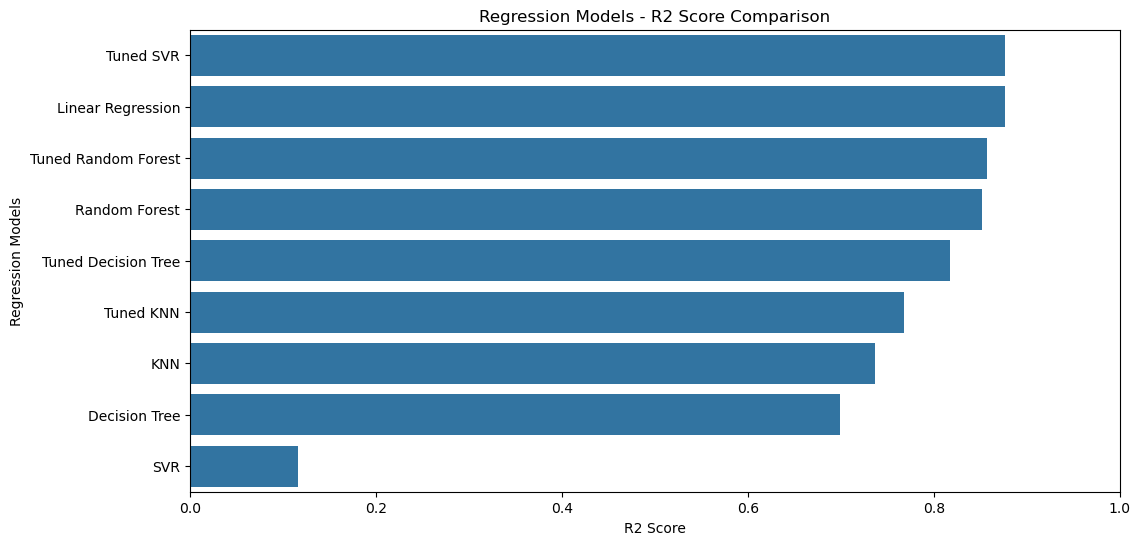

In [ ]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=final_result_df,
    x='R2 Score',
    y='Model Name'
)
plt.title('Regression Models - R2 Score Comparison')
plt.xlabel('R2 Score')
plt.ylabel('Regression Models')
plt.xlim(0, 1)
plt.show()

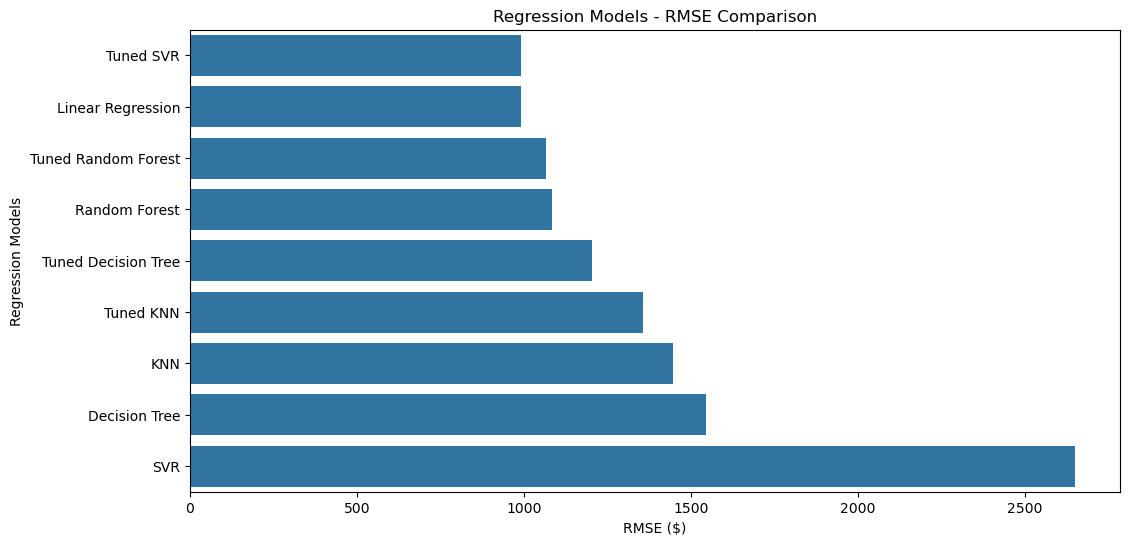

In [ ]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=final_result_df,
    x='RMSE',
    y='Model Name'
)
plt.title('Regression Models - RMSE Comparison')
plt.xlabel('RMSE ($)')
plt.ylabel('Regression Models')
plt.show()

In [462]:
best_model = SVR_best_model

In [470]:
new_car = pd.DataFrame({
    'make_year': [2025],
    'mileage_kmpl': [18.5],
    'engine_cc': [1500],
    'fuel_type': ['Petrol'],
    'owner_count': [2],
    'brand': ['Honda'],
    'transmission': ['Manual'],
    'color': ['White'],
    'service_history': ['Full'],
    'accidents_reported': [0],
    'insurance_valid': ['Yes']
})

In [471]:
new_car_encoded = encoder.transform(
    new_car[categorical_features]
)

new_car_encoded_df = pd.DataFrame(
    new_car_encoded,
    columns=encoded_columns
)

In [472]:
new_car_scaled = scaler.transform(
    new_car[numeric_features]
)

new_car_scaled_df = pd.DataFrame(
    new_car_scaled,
    columns=numeric_features
)

In [473]:
new_car_processed = pd.concat(
    [new_car_scaled_df, new_car_encoded_df],
    axis=1
)

new_car_processed = new_car_processed[
    X_train_processed.columns
]

In [474]:
predicted_price = best_model.predict(new_car_processed)
print("Predicted Used Car Price: $", round(predicted_price[0], 2))

Predicted Used Car Price: $ 8655.83


In [478]:
import joblib
import os

In [476]:
model_data = {
    'model': best_model,
    'encoder': encoder,
    'scaler': scaler,
    'numeric_features': numeric_features,
    'categorical_features': categorical_features,
    'encoded_columns': encoded_columns,
    'feature_columns': X_train_processed.columns.tolist()
}

joblib.dump(
    model_data,
    '../models/used_car_price_model.pkl'
)

print("Model saved successfully!")

Model saved successfully!


In [479]:
os.path.exists('../models/used_car_price_model.pkl')

True

In [480]:
loaded_data = joblib.load('../models/used_car_price_model.pkl')

loaded_model = loaded_data['model']
loaded_encoder = loaded_data['encoder']
loaded_scaler = loaded_data['scaler']

In [481]:
print("Model:", loaded_model)
print("Encoder:", loaded_encoder)
print("Scaler:", loaded_scaler)

Model: SVR(C=100, epsilon=1, kernel='linear')
Encoder: OneHotEncoder(handle_unknown='ignore', sparse_output=False)
Scaler: StandardScaler()


In [ ]:
numeric_features = loaded_data['numeric_features']
categorical_features = loaded_data['categorical_features']
encoded_columns = loaded_data['encoded_columns']
feature_columns = loaded_data['feature_columns']

loaded_encoded = loaded_encoder.transform(
    new_car[categorical_features]
)

loaded_encoded_df = pd.DataFrame(
    loaded_encoded,
    columns=encoded_columns,
    index=new_car.index
)

loaded_scaled = loaded_scaler.transform(
    new_car[numeric_features]
)

loaded_scaled_df = pd.DataFrame(
    loaded_scaled,
    columns=numeric_features,
    index=new_car.index
)

loaded_processed = pd.concat(
    [loaded_scaled_df, loaded_encoded_df],
    axis=1
)

loaded_processed = loaded_processed[feature_columns]

Prediction from saved model: $ 8655.83
